power: poder de ataque, número izquierdo
toughness: poder de defensa, numero derecho
Loyalty: feature de las cartas tipo planeswalkers, cuanto más alto mejor, parecido a la vida.

In [1]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
# función para transformar el dataframe en una matriz de datos utilizable por modelos de scikit-learn

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce") # valores no convertibles se pasan a NaN
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["primary_type"] = x["types"].fillna("").map(
        lambda tipos: tipos.split(",")[0] if tipos else "Unknown"
    )
    x["is_creature"] = x["types"].fillna("").str.contains(
        "Creature", regex=False  # es una creatura?
    ).astype(int)
    x[features_cat] = x[features_cat].fillna("Unknown")
    return x #Devuelve df con algunas categorías a usar por el modelo

In [3]:
x= preparar(train)
y= train['label'].astype(int).to_numpy()

NameError: name 'train' is not defined

# Mismo modelo de regresión logística pero con las features más útiles según Gemini

In [4]:
import pandas as pd

train= pd.read_csv('TP2_train.csv', dtype={'card_id':str, 'set_code':str}) #dtype fuerza a leer esa columna como le indiques, card id son números pero le digo que lo lea como str para evitar problemas tipo id=00123 si lo lee como numero se queda con id=123
test= pd.read_csv('TP2_test.csv', dtype={'card_id':str, 'set_code':str})

features_num= [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "largo_texto", "es_legendaria"
]
features_cat= ["rarity", "color_identity", 'colors']


In [5]:
# Función de limpieza y creación de features

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x= df.copy()

    #Convierte columnas de str a npumeros (lo que no es número pasa a NaN)
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce") #cant tierras totales necesarias para esa carta
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    #Nuevas features
    x['stats_por_mana']= (x['power_numeric'] + x['toughness_numeric']) / (x['mana_value']+1) # +1 para no dividir por 0
    x['simbolos_mana']= x['mana_cost'].fillna('').str.count('{') #cuenta cuantos tipod diferentes de tierras requiere esa carta pero no la cant de cada tipo
    x['es_legendaria']= x['supertypes'].fillna('').str.contains('Legendary', regex=False).astype(int) # Además de la feature rarity hay otra aparte que indica si es legendaria. influye mucho más rarity y de hecho ser legendary le pone restricciones a la carta por lo que podría ser hasta peor.

    #features de texto
    x['oracle_text']= x['oracle_text'].fillna('') #reemplaza celdad vacías por texto vacío. si recibe NaN tira error.
    x['type_line']= x['type_line'].fillna('')
    x['largo_texto']= x['oracle_text'].str.split().str.len() #cuenta cant de palabras.

    #Relleno de vacíos en features categóricas
    x[features_cat]= x[features_cat].fillna('Unknown')

    return x


In [6]:
def props_modelo(c):
    preprocesamiento= ColumnTransformer([ # indica que a cada categoría de feature le hace un procesamiento diferente
        ('numericas', make_pipeline(
            SimpleImputer(strategy='median', add_indicator=True), #rellena los NaN con la meiana de esa feature y crea columna binaria 1 si había un NaN.
            StandardScaler(), # lleva las variables a media 0 y desvío 1 para que la Regresión logística no de más peso a variables con números grandes.
        ), features_num), #le paso la lista de nombres de columnas numericas
        ('categoricas', OneHotEncoder(handle_unknown='ignore'), features_cat), #crea columnas binarias para cada categoría de rarity
        ('texto_reglas', TfidfVectorizer(max_features=1500, ngram_range=(1,2)), 'oracle_text'), #se queda con las palabras (1 palabra o 2 palabras) mas frecuentes 
        ('texto_tipos', TfidfVectorizer(max_features=300), 'type_line'), #uso todos los tipos de carta
    ])
    
    return make_pipeline(
        preprocesamiento,
        LogisticRegression(C=c, solver='liblinear', max_iter=1000),
    )

**Cómo se usa el texto de reglas (`oracle_text`)**

Como la regresión logística solo entiende números, `TfidfVectorizer` convierte el texto de `oracle_text` en una tabla numérica siguiendo tres pasos:

1. **Arma un diccionario:** Lee todas las cartas y elige las 1500 palabras o pares de palabras más repetidas (por ejemplo: `"flash"`, `"flying"`, `"draw a"`, `"destroy target"`).
2. **Crea columnas nuevas:** Agrega 1500 columnas a tu matriz de datos (una por cada palabra o par de palabras elegida).
3. **Asigna puntajes:** Para cada carta, pone un `0` en las palabras que no aparecen en su texto y un número mayor a `0` en las que sí aparecen. Ese número es más alto si la palabra es específica y clave, y más bajo si es una palabra muy común como `"the"`.

Con eso listo, la regresión logística simplemente le asigna un peso positivo o negativo a cada palabra: si las cartas que dicen `"draw a"` suelen tener `label = 1`, esa columna suma puntos a la predicción final.

---

**¿Tiene importancia el tipo de carta?**

Sí, es determinante para no confundir al modelo por tres motivos:

* **Identificar tierras (`Land`):** Las tierras suelen tener vacío el coste de maná (`mana_cost`), el ataque (`power`) y la defensa (`toughness`). Sin el tipo de carta, el modelo vería una fila llena de datos faltantes, cuando en realidad las tierras especiales son de las cartas más jugadas en mazos competitivos (`label = 1`).


* **Velocidad y función:** A igual coste de maná, un `Instant` (que se puede usar en cualquier momento, incluso en el turno del rival) suele tener más valor competitivo que un `Sorcery` o un `Enchantment`.


* **Subtipos relevantes (`subtypes`):** Al vectorizar la columna `type_line` completa, el modelo también detecta subtipos como *Human* o *Wizard*. Muchos mazos competitivos se arman combinando cartas de un mismo subtipo, por lo que ciertas categorías tienen más probabilidad de jugarse que otras.

In [7]:
x= preparar(train)
y= train['label'].astype(int).to_numpy()
z= preparar(test)

folds= GroupKFold(n_splits=5) # parte los datos en 5 folds asegurnado que las cartas del mismo set_code caigan juntas en entrenamiento o validacion
pred_cv= np.full(len(train), np.nan) #crea vector vacío donde se guardan las estimaciónes.

auc=[]

for c in np.arange(0.2,1.2,0.1):

    for numero, (idx_train, idx_val) in enumerate(
        folds.split(x,y, groups= train['set_code']), start=1 #Agrupar los folds con samples del mismo set_code
    ):
        nombres_val= set(train.iloc[idx_val]['name'])
        idx_train= idx_train[
            ~train.iloc[idx_train]['name'].isin(nombres_val).to_numpy()
        ] # borra cartas que estén en ambos grupos (train y validacion) debido a la reimpresion

        modelo=props_modelo(c)
        modelo.fit(x.iloc[idx_train], y[idx_train]) 
        pred_cv[idx_val]= modelo.predict_proba(x.iloc[idx_val])[:,1] #preditc_proba devielve 2 columnas: proba de ser 0 y proba de ser 1, con [:,1] nos quedamos con proba de ser 1 
        print(f'Fold{numero}: {len(idx_val)} cartas evaluadas')

    print(f'AUC (CV): {roc_auc_score(y, pred_cv):.4f}')
    auc.append(roc_auc_score(y,pred_cv))

    #modelo= props_modelo(c)               Esto es para calcular el test, lo hago al final cuando encuentre el mejor modelo
    #modelo.fit(x,y) 
    #score= modelo.predict_proba(z)[:,1]

    #save_path= rf'C:\Users\tocha\Documents\Labo de Datos\TP2\prueba_{c}'
    #pd.DataFrame({'card_id': test['card_id'], 'score': score}).to_csv(save_path, index=False)

Fold1: 1540 cartas evaluadas
Fold2: 1522 cartas evaluadas
Fold3: 1564 cartas evaluadas
Fold4: 1521 cartas evaluadas
Fold5: 1521 cartas evaluadas
AUC (CV): 0.8100
Fold1: 1540 cartas evaluadas
Fold2: 1522 cartas evaluadas
Fold3: 1564 cartas evaluadas
Fold4: 1521 cartas evaluadas
Fold5: 1521 cartas evaluadas
AUC (CV): 0.8123
Fold1: 1540 cartas evaluadas
Fold2: 1522 cartas evaluadas
Fold3: 1564 cartas evaluadas
Fold4: 1521 cartas evaluadas
Fold5: 1521 cartas evaluadas
AUC (CV): 0.8129
Fold1: 1540 cartas evaluadas
Fold2: 1522 cartas evaluadas
Fold3: 1564 cartas evaluadas
Fold4: 1521 cartas evaluadas
Fold5: 1521 cartas evaluadas
AUC (CV): 0.8128
Fold1: 1540 cartas evaluadas
Fold2: 1522 cartas evaluadas
Fold3: 1564 cartas evaluadas
Fold4: 1521 cartas evaluadas
Fold5: 1521 cartas evaluadas
AUC (CV): 0.8124
Fold1: 1540 cartas evaluadas
Fold2: 1522 cartas evaluadas
Fold3: 1564 cartas evaluadas
Fold4: 1521 cartas evaluadas
Fold5: 1521 cartas evaluadas
AUC (CV): 0.8118
Fold1: 1540 cartas evaluadas

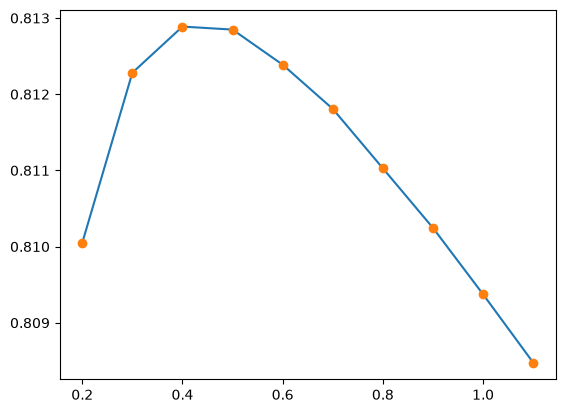

In [8]:
import matplotlib.pyplot as plt

plt.plot(np.arange(0.2,1.2,0.1), auc)
plt.plot(np.arange(0.2,1.2,0.1), auc, 'o')

In [9]:
rng= np.random.default_rng(125)
y_nulo= rng.permutation(y)
pred_cv= np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x,y, groups= train['set_code']), start=1
):
    nombres_val= set(train.iloc[idx_val]['name'])
    idx_train= idx_train[
        ~train.iloc[idx_train]['name'].isin(nombres_val).to_numpy()
    ]

    modelo=props_modelo(0.4)
    modelo.fit(x.iloc[idx_train], y[idx_train]) 
    pred_cv[idx_val]= modelo.predict_proba(x.iloc[idx_val])[:,1] 

print(f'mejor modelo actual: AUC (CV): {roc_auc_score(y, pred_cv):.4f}')
auc.append(roc_auc_score(y,pred_cv))

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x,y_nulo, groups= train['set_code']), start=1
):
    nombres_val= set(train.iloc[idx_val]['name'])
    idx_train= idx_train[
        ~train.iloc[idx_train]['name'].isin(nombres_val).to_numpy()
    ]

    modelo=props_modelo(0.4)
    modelo.fit(x.iloc[idx_train], y_nulo[idx_train]) 
    pred_cv[idx_val]= modelo.predict_proba(x.iloc[idx_val])[:,1] 

print(f'modelo nulo: AUC (CV): {roc_auc_score(y_nulo, pred_cv):.4f}')
auc.append(roc_auc_score(y_nulo,pred_cv))

mejor modelo actual: AUC (CV): 0.8129
modelo nulo: AUC (CV): 0.5067


# Método combinar modelos

4. Ajustar hiperparámetros y combinar (Ensemble)

Los árboles suelen sobreajustar si hay cientos de columnas de texto generadas por TF-IDF, mientras que la regresión logística maneja muy bien el texto.

Una estrategia muy efectiva al final es entrenar ambos por separado (una regresión logística fuerte en texto + un LightGBM/HistGradientBoosting fuerte en variables numéricas y categóricas) y promediar las probabilidades que devuelven en predict_proba. Como la métrica es ROC AUC, promediar probabilidades bien calibradas casi siempre supera a cualquier modelo individual.

In [10]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder

features_num = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "largo_texto", "es_legendaria"
]
features_cat = ["rarity", "color_identity", "colors"]

# Modelo 1: Regresión Logística (fuerte en texto detallado)
def crear_modelo_lineal():
    preprocesamiento = ColumnTransformer([
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat),
        ("texto_reglas", TfidfVectorizer(max_features=1500, ngram_range=(1, 2)), "oracle_text"),
        ("texto_tipos", TfidfVectorizer(max_features=300), "type_line"),
    ])
    return make_pipeline(
        preprocesamiento,
        LogisticRegression(C=0.3, solver="liblinear", max_iter=1000),
    )

# Modelo 2: Boosting de Árboles (fuerte en cruces no lineales y NaNs)
def crear_modelo_arboles():
    # sparse_threshold=0 convierte la matriz en densa (requisito de HistGradientBoosting)
    preprocesamiento = ColumnTransformer([
        ("numericas", "passthrough", features_num), # pasa los NaN directo sin imputar
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat),
        ("texto_reglas", TfidfVectorizer(max_features=150, ngram_range=(1, 2)), "oracle_text"),
        ("texto_tipos", TfidfVectorizer(max_features=50), "type_line"),
    ], sparse_threshold=0)
    
    return make_pipeline(
        preprocesamiento,
        HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, max_leaf_nodes=31, random_state=42),
    )

# Validación cruzada guardando las predicciones de cada modelo por separado
folds = GroupKFold(n_splits=5)
pred_lineal = np.full(len(train), np.nan)
pred_arboles = np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[
        ~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()
    ]
    
    # Entrena y predice Modelo 1
    m_lin = crear_modelo_lineal()
    m_lin.fit(x.iloc[idx_train], y[idx_train])
    pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]
    
    # Entrena y predice Modelo 2
    m_arb = crear_modelo_arboles()
    m_arb.fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]
    
    print(f"Fold {numero} completado")

# Comparamos los resultados
pred_promedio = 0.5 * pred_lineal + 0.5 * pred_arboles

print(f"AUC Regresión Logística: {roc_auc_score(y, pred_lineal):.4f}")
print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")
print(f"AUC Promedio (50/50):    {roc_auc_score(y, pred_promedio):.4f}")

Fold 1 completado
Fold 2 completado
Fold 3 completado
Fold 4 completado
Fold 5 completado
AUC Regresión Logística: 0.8123
AUC Árboles (Boosting):  0.7906
AUC Promedio (50/50):    0.8155


In [11]:
# Entrenamiento final con todos los datos para entregar
m_lin_final = crear_modelo_lineal().fit(x, y)
m_arb_final = crear_modelo_arboles().fit(x, y)

score_final = 0.5 * m_lin_final.predict_proba(z)[:, 1] + 0.5 * m_arb_final.predict_proba(z)[:, 1]

save_path = r"C:\Users\tocha\Documents\Labo de Datos\TP2\grupoX.csv"
pd.DataFrame({"card_id": test["card_id"], "score": score_final}).to_csv(save_path, index=False)

In [12]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

features_num = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "mana_coloreado", "largo_texto",
    "lineas_texto", "cant_colores", "anio", "es_legendaria", "tiene_estrella"
]
features_cat = ["rarity", "color_identity", "colors", "primary_type"]

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["colors"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year # tiene en cuenta la inflación de poder
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x[features_cat] = x[features_cat].fillna("Unknown")
    return x

# Patrón que conserva números de 1 dígito, símbolos {T}/{U} y costes +1/-2
patron_tokens = r"(?u)\b\w+\b|\{[^}]+\}|[+-]\d+"

def crear_modelo_lineal():
    preprocesamiento = ColumnTransformer([
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat),
        ("texto_reglas", TfidfVectorizer(
            max_features=2500, ngram_range=(1, 2), token_pattern=patron_tokens, sublinear_tf=True
        ), "oracle_text"),
        ("texto_tipos", TfidfVectorizer(max_features=400), "type_line"),
    ])
    return make_pipeline(
        preprocesamiento,
        LogisticRegression(C=0.4, solver="liblinear", max_iter=1000),
    )

def crear_modelo_arboles():
    preprocesamiento = ColumnTransformer([
        ("numericas", "passthrough", features_num),
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat),
        # Comprimimos el texto en 30 conceptos densos con SVD para que el árbol no sobreajuste
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    # Le indicamos al árbol los índices exactos de las columnas categóricas
    idx_cat = list(range(len(features_num), len(features_num) + len(features_cat)))
    return make_pipeline(
        preprocesamiento,
        HistGradientBoostingClassifier(
            categorical_features=idx_cat,
            max_iter=250,
            learning_rate=0.03,
            max_leaf_nodes=31,
            min_samples_leaf=25,
            l2_regularization=1.0,
            random_state=42
        ),
    )

# Preparación y Validación Cruzada
x = preparar(train)
z = preparar(test)
y = train["label"].astype(int).to_numpy()

folds = GroupKFold(n_splits=5)
pred_lineal = np.full(len(train), np.nan)
pred_arboles = np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

    m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
    pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

    m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]

print(f"AUC Regresión Logística: {roc_auc_score(y, pred_lineal):.4f}")
print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")

# Búsqueda del mejor peso w para combinar ambos modelos
mejor_w, mejor_auc = 0.5, 0.0
for w in np.linspace(0, 1, 101):
    auc = roc_auc_score(y, w * pred_lineal + (1 - w) * pred_arboles)
    if auc > mejor_auc:
        mejor_auc, mejor_w = auc, w

print(f"Mejor combinación ({mejor_w:.2f} Lineal + {1-mejor_w:.2f} Árboles) -> AUC: {mejor_auc:.4f}")

AUC Regresión Logística: 0.8232
AUC Árboles (Boosting):  0.8207
Mejor combinación (0.46 Lineal + 0.54 Árboles) -> AUC: 0.8338


In [13]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

features_num = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "mana_coloreado", "largo_texto",
    "lineas_texto", "cant_colores", "es_legendaria", "tiene_estrella"
]
features_cat = ["rarity", "color_identity", "colors", "primary_type"]

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["colors"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x[features_cat] = x[features_cat].fillna("Unknown")
    return x

# Patrón que conserva números de 1 dígito, símbolos {T}/{U} y costes +1/-2
patron_tokens = r"(?u)\b\w+\b|\{[^}]+\}|[+-]\d+"

def crear_modelo_lineal():
    preprocesamiento = ColumnTransformer([
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat),
        ("texto_reglas", TfidfVectorizer(
            max_features=2500, ngram_range=(1, 2), token_pattern=patron_tokens, sublinear_tf=True
        ), "oracle_text"),
        ("texto_tipos", TfidfVectorizer(max_features=400), "type_line"),
    ])
    return make_pipeline(
        preprocesamiento,
        LogisticRegression(C=0.4, solver="liblinear", max_iter=1000),
    )

def crear_modelo_arboles():
    preprocesamiento = ColumnTransformer([
        ("numericas", "passthrough", features_num),
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat),
        # Comprimimos el texto en 30 conceptos densos con SVD para que el árbol no sobreajuste
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    # Le indicamos al árbol los índices exactos de las columnas categóricas
    idx_cat = list(range(len(features_num), len(features_num) + len(features_cat)))
    return make_pipeline(
        preprocesamiento,
        HistGradientBoostingClassifier(
            categorical_features=idx_cat,
            max_iter=250,
            learning_rate=0.03,
            max_leaf_nodes=31,
            min_samples_leaf=25,
            l2_regularization=1.0,
            random_state=42
        ),
    )

# Preparación y Validación Cruzada
x = preparar(train)
z = preparar(test)
y = train["label"].astype(int).to_numpy()

folds = GroupKFold(n_splits=5)
pred_lineal = np.full(len(train), np.nan)
pred_arboles = np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

    m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
    pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

    m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]

print(f"AUC Regresión Logística: {roc_auc_score(y, pred_lineal):.4f}")
print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")

# Búsqueda del mejor peso w para combinar ambos modelos
mejor_w, mejor_auc = 0.5, 0.0
for w in np.linspace(0, 1, 101):
    auc = roc_auc_score(y, w * pred_lineal + (1 - w) * pred_arboles)
    if auc > mejor_auc:
        mejor_auc, mejor_w = auc, w

print(f"Mejor combinación ({mejor_w:.2f} Lineal + {1-mejor_w:.2f} Árboles) -> AUC: {mejor_auc:.4f}")

AUC Regresión Logística: 0.8160
AUC Árboles (Boosting):  0.8108
Mejor combinación (0.50 Lineal + 0.50 Árboles) -> AUC: 0.8248


Feature ingeniering:

da mejor con anio

In [14]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

features_num = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "mana_coloreado", "largo_texto",
    "lineas_texto", "cant_colores", "anio", "es_legendaria", "tiene_estrella"
]
features_cat = ["rarity", "color_identity", "colors", "primary_type"]

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["color_identity"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year # tiene en cuenta la inflación de poder
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x[features_cat] = x[features_cat].fillna("Unknown")
    return x

# Patrón que conserva números de 1 dígito, símbolos {T}/{U} y costes +1/-2
patron_tokens = r"(?u)\b\w+\b|\{[^}]+\}|[+-]\d+"

def crear_modelo_lineal():
    preprocesamiento = ColumnTransformer([
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat),
        ("texto_reglas", TfidfVectorizer(
            max_features=2500, ngram_range=(1, 2), token_pattern=patron_tokens, sublinear_tf=True
        ), "oracle_text"),
        ("texto_tipos", TfidfVectorizer(max_features=400), "type_line"),
    ])
    return make_pipeline(
        preprocesamiento,
        LogisticRegression(C=0.4, solver="liblinear", max_iter=1000),
    )

def crear_modelo_arboles():
    preprocesamiento = ColumnTransformer([
        ("numericas", "passthrough", features_num),
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat),
        # Comprimimos el texto en 30 conceptos densos con SVD para que el árbol no sobreajuste
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    # Le indicamos al árbol los índices exactos de las columnas categóricas
    idx_cat = list(range(len(features_num), len(features_num) + len(features_cat)))
    return make_pipeline(
        preprocesamiento,
        HistGradientBoostingClassifier(
            categorical_features=idx_cat,
            max_iter=250,
            learning_rate=0.03,
            max_leaf_nodes=31,
            min_samples_leaf=25,
            l2_regularization=1.0,
            random_state=42
        ),
    )

# Preparación y Validación Cruzada
x = preparar(train)
z = preparar(test)
y = train["label"].astype(int).to_numpy()

folds = GroupKFold(n_splits=5)
pred_lineal = np.full(len(train), np.nan)
pred_arboles = np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

    m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
    pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

    m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]

print(f"AUC Regresión Logística: {roc_auc_score(y, pred_lineal):.4f}")
print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")

# Búsqueda del mejor peso w para combinar ambos modelos
mejor_w, mejor_auc = 0.5, 0.0
for w in np.linspace(0, 1, 101):
    auc = roc_auc_score(y, w * pred_lineal + (1 - w) * pred_arboles)
    if auc > mejor_auc:
        mejor_auc, mejor_w = auc, w

print(f"Mejor combinación ({mejor_w:.2f} Lineal + {1-mejor_w:.2f} Árboles) -> AUC: {mejor_auc:.4f}")

AUC Regresión Logística: 0.8237
AUC Árboles (Boosting):  0.8224
Mejor combinación (0.44 Lineal + 0.56 Árboles) -> AUC: 0.8349


prueba de si conviene usar colors o color identidad.  
para eso me fijo cuál tiene auc más alto en cada fold

In [15]:
def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["color_identity"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year # tiene en cuenta la inflación de poder
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x[features_cat] = x[features_cat].fillna("Unknown")
    return x

# Patrón que conserva números de 1 dígito, símbolos {T}/{U} y costes +1/-2
patron_tokens = r"(?u)\b\w+\b|\{[^}]+\}|[+-]\d+"

# Preparación y Validación Cruzada
x = preparar(train)
z = preparar(test)
y = train["label"].astype(int).to_numpy()


folds = GroupKFold(n_splits=5)
pred_lineal = np.full(len(train), np.nan)
pred_arboles = np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

    m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
    pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

    m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]

    # Calculamos el AUC solo para las cartas de este fold
    auc_lin = roc_auc_score(y[idx_val], pred_lineal[idx_val])
    auc_arb = roc_auc_score(y[idx_val], pred_arboles[idx_val])
    auc_mix = roc_auc_score(y[idx_val], 0.5 * pred_lineal[idx_val] + 0.5 * pred_arboles[idx_val])

    print(f"Fold {numero} -> Lineal: {auc_lin:.4f} | Árboles: {auc_arb:.4f} | Mix 50/50: {auc_mix:.4f}")

Fold 1 -> Lineal: 0.8347 | Árboles: 0.8368 | Mix 50/50: 0.8483
Fold 2 -> Lineal: 0.8100 | Árboles: 0.8079 | Mix 50/50: 0.8220
Fold 3 -> Lineal: 0.8288 | Árboles: 0.8307 | Mix 50/50: 0.8411
Fold 4 -> Lineal: 0.8267 | Árboles: 0.8361 | Mix 50/50: 0.8399
Fold 5 -> Lineal: 0.8211 | Árboles: 0.8251 | Mix 50/50: 0.8319


In [16]:
def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["colors"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year # tiene en cuenta la inflación de poder
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x[features_cat] = x[features_cat].fillna("Unknown")
    return x

# Patrón que conserva números de 1 dígito, símbolos {T}/{U} y costes +1/-2
patron_tokens = r"(?u)\b\w+\b|\{[^}]+\}|[+-]\d+"

# Preparación y Validación Cruzada
x = preparar(train)
z = preparar(test)
y = train["label"].astype(int).to_numpy()

folds = GroupKFold(n_splits=5)
pred_lineal = np.full(len(train), np.nan)
pred_arboles = np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

    m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
    pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

    m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]

    # Calculamos el AUC solo para las cartas de este fold
    auc_lin = roc_auc_score(y[idx_val], pred_lineal[idx_val])
    auc_arb = roc_auc_score(y[idx_val], pred_arboles[idx_val])
    auc_mix = roc_auc_score(y[idx_val], 0.5 * pred_lineal[idx_val] + 0.5 * pred_arboles[idx_val])

    print(f"Fold {numero} -> Lineal: {auc_lin:.4f} | Árboles: {auc_arb:.4f} | Mix 50/50: {auc_mix:.4f}")

Fold 1 -> Lineal: 0.8327 | Árboles: 0.8352 | Mix 50/50: 0.8452
Fold 2 -> Lineal: 0.8093 | Árboles: 0.8035 | Mix 50/50: 0.8198
Fold 3 -> Lineal: 0.8254 | Árboles: 0.8318 | Mix 50/50: 0.8399
Fold 4 -> Lineal: 0.8278 | Árboles: 0.8364 | Mix 50/50: 0.8409
Fold 5 -> Lineal: 0.8221 | Árboles: 0.8226 | Mix 50/50: 0.8316


Se ve una ligera ventaja del modelo que usa color identity pero nada muy grande, de hecho es más grande el salto entre folds que entre métodos.  
usaré el color identity pues tiene más samples con datos.  


pruebo que da usando solo los árboles de decisión

In [17]:
features_num = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "mana_coloreado", "largo_texto",
    "lineas_texto", "cant_colores", "anio", "es_legendaria", "tiene_estrella"
]
features_cat = ["rarity", "color_identity", "colors", "primary_type"]

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["color_identity"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year # tiene en cuenta la inflación de poder
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x[features_cat] = x[features_cat].fillna("Unknown")
    return x

# Patrón que conserva números de 1 dígito, símbolos {T}/{U} y costes +1/-2
patron_tokens = r"(?u)\b\w+\b|\{[^}]+\}|[+-]\d+"

def crear_modelo_arboles():
    preprocesamiento = ColumnTransformer([
        ("numericas", "passthrough", features_num),
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat),
        # Comprimimos el texto en 30 conceptos densos con SVD para que el árbol no sobreajuste
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    # Le indicamos al árbol los índices exactos de las columnas categóricas
    idx_cat = list(range(len(features_num), len(features_num) + len(features_cat)))
    return make_pipeline(
        preprocesamiento,
        HistGradientBoostingClassifier(
            categorical_features=idx_cat,
            max_iter=250,
            learning_rate=0.03,
            max_leaf_nodes=31,
            min_samples_leaf=25,
            l2_regularization=1.0,
            random_state=42
        ),
    )

# Preparación y Validación Cruzada
x = preparar(train)
z = preparar(test)
y = train["label"].astype(int).to_numpy()

folds = GroupKFold(n_splits=5)
pred_arboles = np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

    m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]

print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")

AUC Árboles (Boosting):  0.8224


si bien usando árboles da mejor que usando reg logística da peor que combinando ambas.  
recuerdo que el promedio es sobre las probs del label por lo que no va a quedar entre ambos auc sino que lo puede superar.

Vuelvo a pegar el mejor modelo obtenido hasta ahora

In [18]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

features_num = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "mana_coloreado", "largo_texto",
    "lineas_texto", "cant_colores", "anio", "es_legendaria", "tiene_estrella"
]
features_cat = ["rarity", "color_identity", "colors", "primary_type"]

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["color_identity"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year # tiene en cuenta la inflación de poder
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x[features_cat] = x[features_cat].fillna("Unknown")
    return x

# Patrón que conserva números de 1 dígito, símbolos {T}/{U} y costes +1/-2
patron_tokens = r"(?u)\b\w+\b|\{[^}]+\}|[+-]\d+"

def crear_modelo_lineal():
    preprocesamiento = ColumnTransformer([
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat),
        ("texto_reglas", TfidfVectorizer(
            max_features=2500, ngram_range=(1, 2), token_pattern=patron_tokens, sublinear_tf=True
        ), "oracle_text"),
        ("texto_tipos", TfidfVectorizer(max_features=400), "type_line"),
    ])
    return make_pipeline(
        preprocesamiento,
        LogisticRegression(C=0.4, solver="liblinear", max_iter=1000),
    )

def crear_modelo_arboles():
    preprocesamiento = ColumnTransformer([
        ("numericas", "passthrough", features_num),
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat),
        # Comprimimos el texto en 30 conceptos densos con SVD para que el árbol no sobreajuste
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    # Le indicamos al árbol los índices exactos de las columnas categóricas
    idx_cat = list(range(len(features_num), len(features_num) + len(features_cat)))
    return make_pipeline(
        preprocesamiento,
        HistGradientBoostingClassifier(
            categorical_features=idx_cat,
            max_iter=250,
            learning_rate=0.03,
            max_leaf_nodes=31,
            min_samples_leaf=25,
            l2_regularization=1.0,
            random_state=42
        ),
    )

# Preparación y Validación Cruzada
x = preparar(train)
z = preparar(test)
y = train["label"].astype(int).to_numpy()

folds = GroupKFold(n_splits=5)
pred_lineal = np.full(len(train), np.nan)
pred_arboles = np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

    m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
    pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

    m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]

print(f"AUC Regresión Logística: {roc_auc_score(y, pred_lineal):.4f}")
print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")

# Búsqueda del mejor peso w para combinar ambos modelos
mejor_w, mejor_auc = 0.5, 0.0
for w in np.linspace(0, 1, 101):
    auc = roc_auc_score(y, w * pred_lineal + (1 - w) * pred_arboles)
    if auc > mejor_auc:
        mejor_auc, mejor_w = auc, w

print(f"Mejor combinación ({mejor_w:.2f} Lineal + {1-mejor_w:.2f} Árboles) -> AUC: {mejor_auc:.4f}")

AUC Regresión Logística: 0.8237
AUC Árboles (Boosting):  0.8224
Mejor combinación (0.44 Lineal + 0.56 Árboles) -> AUC: 0.8349


Intento crear una feature que ayude a la regresión logística pero no la uso para los árboles porque empeora

In [19]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

features_num = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "mana_coloreado", "largo_texto",
    "lineas_texto", "cant_colores", "anio", "es_legendaria", "tiene_estrella"
]

# El lineal recibe la feature combinada
features_cat_lineal = ["rarity", "color_identity", "colors", "primary_type", "rareza_tipo"]

# El árbol recibe las columnas separadas originales
features_cat_arboles = ["rarity", "color_identity", "colors", "primary_type"]

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["color_identity"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year # tiene en cuenta la inflación de poder
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)
    

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x["rareza_tipo"] = x["rarity"].astype(str) + "_" + x["primary_type"]
    x[features_cat] = x[features_cat].fillna("Unknown")

    return x

# Patrón que conserva números de 1 dígito, símbolos {T}/{U} y costes +1/-2
patron_tokens = r"(?u)\b\w+\b|\{[^}]+\}|[+-]\d+"

def crear_modelo_lineal():
    preprocesamiento = ColumnTransformer([
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat_lineal),
        ("texto_reglas", TfidfVectorizer(
            max_features=2500, ngram_range=(1, 2), token_pattern=patron_tokens, sublinear_tf=True
        ), "oracle_text"),
        ("texto_tipos", TfidfVectorizer(max_features=400), "type_line"),
    ])
    return make_pipeline(
        preprocesamiento,
        LogisticRegression(C=0.4, solver="liblinear", max_iter=1000),
    )

def crear_modelo_arboles():
    preprocesamiento = ColumnTransformer([
        ("numericas", "passthrough", features_num),
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat_arboles),
        # Comprimimos el texto en 30 conceptos densos con SVD para que el árbol no sobreajuste
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    # Le indicamos al árbol los índices exactos de las columnas categóricas
    idx_cat = list(range(len(features_num), len(features_num) + len(features_cat)))
    return make_pipeline(
        preprocesamiento,
        HistGradientBoostingClassifier(
            categorical_features=idx_cat,
            max_iter=250,
            learning_rate=0.03,
            max_leaf_nodes=31,
            min_samples_leaf=25,
            l2_regularization=1.0,
            random_state=42
        ),
    )

# Preparación y Validación Cruzada
x = preparar(train)
z = preparar(test)
y = train["label"].astype(int).to_numpy()

folds = GroupKFold(n_splits=5)
pred_lineal = np.full(len(train), np.nan)
pred_arboles = np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

    m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
    pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

    m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]

print(f"AUC Regresión Logística: {roc_auc_score(y, pred_lineal):.4f}")
print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")

# Búsqueda del mejor peso w para combinar ambos modelos
mejor_w, mejor_auc = 0.5, 0.0
for w in np.linspace(0, 1, 101):
    auc = roc_auc_score(y, w * pred_lineal + (1 - w) * pred_arboles)
    if auc > mejor_auc:
        mejor_auc, mejor_w = auc, w

print(f"Mejor combinación ({mejor_w:.2f} Lineal + {1-mejor_w:.2f} Árboles) -> AUC: {mejor_auc:.4f}")

AUC Regresión Logística: 0.8254
AUC Árboles (Boosting):  0.8224
Mejor combinación (0.48 Lineal + 0.52 Árboles) -> AUC: 0.8358


diferencio entre que cueste 0 tierras y que sea una tierra con coste vacío

In [20]:
features_num = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "mana_coloreado", "largo_texto",
    "lineas_texto", "cant_colores", "anio", "es_legendaria", "tiene_estrella", 'sin_coste_mana'
]

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["color_identity"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year # tiene en cuenta la inflación de poder
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)
    x["sin_coste_mana"] = x["mana_cost"].isna().astype(int)

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x["rareza_tipo"] = x["rarity"].astype(str) + "_" + x["primary_type"]
    x[features_cat] = x[features_cat].fillna("Unknown")

    return x

# Preparación y Validación Cruzada
x = preparar(train)
z = preparar(test)
y = train["label"].astype(int).to_numpy()

folds = GroupKFold(n_splits=5)
pred_lineal = np.full(len(train), np.nan)
pred_arboles = np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

    m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
    pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

    m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]

print(f"AUC Regresión Logística: {roc_auc_score(y, pred_lineal):.4f}")
print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")

# Búsqueda del mejor peso w para combinar ambos modelos
mejor_w, mejor_auc = 0.5, 0.0
for w in np.linspace(0, 1, 101):
    auc = roc_auc_score(y, w * pred_lineal + (1 - w) * pred_arboles)
    if auc > mejor_auc:
        mejor_auc, mejor_w = auc, w

print(f"Mejor combinación ({mejor_w:.2f} Lineal + {1-mejor_w:.2f} Árboles) -> AUC: {mejor_auc:.4f}")

AUC Regresión Logística: 0.8255
AUC Árboles (Boosting):  0.8224
Mejor combinación (0.47 Lineal + 0.53 Árboles) -> AUC: 0.8358


creo una feature por cada color

In [21]:
features_num = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "mana_coloreado", "largo_texto",
    "lineas_texto", "cant_colores", "anio", "es_legendaria", "tiene_estrella",
    "sin_coste_mana",
    "color_W", "color_U", "color_B", "color_R", "color_G" 
]

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
# Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") 
    x["cant_colores"] = x["color_identity"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) 
    
    # --- NUEVO BLOQUE: Fragmentación de colores ---
    for c in ["W", "U", "B", "R", "G"]:
        x[f"color_{c}"] = x["color_identity"].fillna("").str.contains(c, regex=False).astype(int)
    # ----------------------------------------------
    
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    # ... sigue igual con tiene_estrella
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)
    x["sin_coste_mana"] = x["mana_cost"].isna().astype(int)

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x["rareza_tipo"] = x["rarity"].astype(str) + "_" + x["primary_type"]
    x[features_cat] = x[features_cat].fillna("Unknown")

    return x

# Preparación y Validación Cruzada
x = preparar(train)
z = preparar(test)
y = train["label"].astype(int).to_numpy()

folds = GroupKFold(n_splits=5)
pred_lineal = np.full(len(train), np.nan)
pred_arboles = np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

    m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
    pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

    m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]

print(f"AUC Regresión Logística: {roc_auc_score(y, pred_lineal):.4f}")
print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")

# Búsqueda del mejor peso w para combinar ambos modelos
mejor_w, mejor_auc = 0.5, 0.0
for w in np.linspace(0, 1, 101):
    auc = roc_auc_score(y, w * pred_lineal + (1 - w) * pred_arboles)
    if auc > mejor_auc:
        mejor_auc, mejor_w = auc, w

print(f"Mejor combinación ({mejor_w:.2f} Lineal + {1-mejor_w:.2f} Árboles) -> AUC: {mejor_auc:.4f}")

AUC Regresión Logística: 0.8254
AUC Árboles (Boosting):  0.8190
Mejor combinación (0.48 Lineal + 0.52 Árboles) -> AUC: 0.8342


No funcionó, descarto estas features.  
correr celdas anteriores pero no la anterior.  
arreglo cosas del modelo de arboles:

In [22]:
def crear_modelo_arboles():
    preprocesamiento = ColumnTransformer([
        ("numericas", "passthrough", features_num),
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat_arboles),
        # Comprimimos el texto en 30 conceptos densos con SVD para que el árbol no sobreajuste
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    # Le indicamos al árbol los índices exactos de las columnas categóricas
    idx_cat = list(range(len(features_num), len(features_num) + len(features_cat_arboles)))
    return make_pipeline(
        preprocesamiento,
        HistGradientBoostingClassifier(
            categorical_features=idx_cat,
            max_iter=250,
            learning_rate=0.03,
            max_leaf_nodes=31,
            min_samples_leaf=25,
            l2_regularization=1.0,
            random_state=42
        ),
    )

# Preparación y Validación Cruzada
x = preparar(train)
z = preparar(test)
y = train["label"].astype(int).to_numpy()

folds = GroupKFold(n_splits=5)
pred_lineal = np.full(len(train), np.nan)
pred_arboles = np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

    m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
    pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

    m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]

print(f"AUC Regresión Logística: {roc_auc_score(y, pred_lineal):.4f}")
print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")

# Búsqueda del mejor peso w para combinar ambos modelos
mejor_w, mejor_auc = 0.5, 0.0
for w in np.linspace(0, 1, 101):
    auc = roc_auc_score(y, w * pred_lineal + (1 - w) * pred_arboles)
    if auc > mejor_auc:
        mejor_auc, mejor_w = auc, w

print(f"Mejor combinación ({mejor_w:.2f} Lineal + {1-mejor_w:.2f} Árboles) -> AUC: {mejor_auc:.4f}")

AUC Regresión Logística: 0.8254
AUC Árboles (Boosting):  0.8190
Mejor combinación (0.48 Lineal + 0.52 Árboles) -> AUC: 0.8342


evito rellenar las cartas que no tienen power/thougness con el promedio. ahroa serán 0.  
arboles detecta nan de base por lo que a ese modelo no le paso 0 (arruinaba el auc).  

In [23]:
def modelar ():

    # Preparación y Validación Cruzada
    x = preparar(train)
    z = preparar(test)
    y = train["label"].astype(int).to_numpy()

    folds = GroupKFold(n_splits=5)
    pred_lineal = np.full(len(train), np.nan)
    pred_arboles = np.full(len(train), np.nan)

    for numero, (idx_train, idx_val) in enumerate(
        folds.split(x, y, groups=train["set_code"]), start=1
    ):
        nombres_val = set(train.iloc[idx_val]["name"])
        idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

        m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
        pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

        m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
        pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]

    print(f"AUC Regresión Logística: {roc_auc_score(y, pred_lineal):.4f}")
    print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")

    # Búsqueda del mejor peso w para combinar ambos modelos
    mejor_w, mejor_auc = 0.5, 0.0
    for w in np.linspace(0, 1, 101):
        auc = roc_auc_score(y, w * pred_lineal + (1 - w) * pred_arboles)
        if auc > mejor_auc:
            mejor_auc, mejor_w = auc, w

    print(f"Mejor combinación ({mejor_w:.2f} Lineal + {1-mejor_w:.2f} Árboles) -> AUC: {mejor_auc:.4f}")

In [24]:
def crear_modelo_lineal():
    preprocesamiento = ColumnTransformer([
        ("numericas", make_pipeline(
            # ¡Acá está la magia! Rellena los NaN con 0 solo para el modelo lineal
            SimpleImputer(strategy="constant", fill_value=0, add_indicator=True),
            StandardScaler(),
        ), features_num),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat_lineal),
        ("texto_reglas", TfidfVectorizer(
            max_features=2500, ngram_range=(1, 2), token_pattern=patron_tokens, sublinear_tf=True
        ), "oracle_text"),
        ("texto_tipos", TfidfVectorizer(max_features=400), "type_line"),
    ])
    return make_pipeline(
        preprocesamiento,
        LogisticRegression(C=0.4, solver="liblinear", max_iter=1000),
    )

modelar()

AUC Regresión Logística: 0.8253
AUC Árboles (Boosting):  0.8190
Mejor combinación (0.50 Lineal + 0.50 Árboles) -> AUC: 0.8342


empeoró. terrible.  
Vuelvo al modelo lineal de antes

In [25]:
def crear_modelo_lineal():
    preprocesamiento = ColumnTransformer([
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat_lineal),
        ("texto_reglas", TfidfVectorizer(
            max_features=2500, ngram_range=(1, 2), token_pattern=patron_tokens, sublinear_tf=True
        ), "oracle_text"),
        ("texto_tipos", TfidfVectorizer(max_features=400), "type_line"),
    ])
    return make_pipeline(
        preprocesamiento,
        LogisticRegression(C=0.4, solver="liblinear", max_iter=1000),
    )

veo las stats según el set.

In [26]:
features_num = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "mana_coloreado", "largo_texto",
    "lineas_texto", "cant_colores", "anio", "es_legendaria", "tiene_estrella",
    "sin_coste_mana",
    "mana_vs_set", "power_vs_set", "toughness_vs_set"
]

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["color_identity"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year # tiene en cuenta la inflación de poder
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)
    x["sin_coste_mana"] = x["mana_cost"].isna().astype(int)
  
    # Calculamos la media de maná, poder y resistencia para cada set_code
    promedios_set = x.groupby("set_code")[["mana_value", "power_numeric", "toughness_numeric"]].transform("mean")
    
    # Restamos el promedio a la carta actual. 
    # Si da positivo, es más cara/fuerte que el promedio de su expansión.
    x["mana_vs_set"] = x["mana_value"] - promedios_set["mana_value"]
    x["power_vs_set"] = x["power_numeric"] - promedios_set["power_numeric"]
    x["toughness_vs_set"] = x["toughness_numeric"] - promedios_set["toughness_numeric"]

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x["rareza_tipo"] = x["rarity"].astype(str) + "_" + x["primary_type"]
    x[features_cat] = x[features_cat].fillna("Unknown")

    return x

def crear_modelo_arboles():
    preprocesamiento = ColumnTransformer([
        ("numericas", "passthrough", features_num),
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat_arboles),
        # Comprimimos el texto en 30 conceptos densos con SVD para que el árbol no sobreajuste
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    # Le indicamos al árbol los índices exactos de las columnas categóricas
    idx_cat = list(range(len(features_num), len(features_num) + len(features_cat_arboles)))
    return make_pipeline(
        preprocesamiento,
        HistGradientBoostingClassifier(
            categorical_features=idx_cat,
            max_iter=250,
            learning_rate=0.03,
            max_leaf_nodes=31,
            min_samples_leaf=25,
            l2_regularization=1.0,
            random_state=42
        ),
    )

# Preparación y Validación Cruzada
x = preparar(train)
z = preparar(test)
y = train["label"].astype(int).to_numpy()

folds = GroupKFold(n_splits=5)
pred_lineal = np.full(len(train), np.nan)
pred_arboles = np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

    m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
    pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

    m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]

print(f"AUC Regresión Logística: {roc_auc_score(y, pred_lineal):.4f}")
print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")

# Búsqueda del mejor peso w para combinar ambos modelos
mejor_w, mejor_auc = 0.5, 0.0
for w in np.linspace(0, 1, 101):
    auc = roc_auc_score(y, w * pred_lineal + (1 - w) * pred_arboles)
    if auc > mejor_auc:
        mejor_auc, mejor_w = auc, w

print(f"Mejor combinación ({mejor_w:.2f} Lineal + {1-mejor_w:.2f} Árboles) -> AUC: {mejor_auc:.4f}")

modelar()

AUC Regresión Logística: 0.8246
AUC Árboles (Boosting):  0.8178
Mejor combinación (0.51 Lineal + 0.49 Árboles) -> AUC: 0.8335
AUC Regresión Logística: 0.8246
AUC Árboles (Boosting):  0.8178
Mejor combinación (0.51 Lineal + 0.49 Árboles) -> AUC: 0.8335


No funcionó, vuelvo para atrás

In [27]:
features_num = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "mana_coloreado", "largo_texto",
    "lineas_texto", "cant_colores", "anio", "es_legendaria", "tiene_estrella",
    "sin_coste_mana",
]

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["color_identity"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year # tiene en cuenta la inflación de poder
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)
    x["sin_coste_mana"] = x["mana_cost"].isna().astype(int)

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x["rareza_tipo"] = x["rarity"].astype(str) + "_" + x["primary_type"]
    x[features_cat] = x[features_cat].fillna("Unknown")

    return x

uso palabras clave para ayudar a los arboles.  
no se si esto vale puesto que gemini sabe que palabras son usadas en competitivo.  
separo las features que le doy a cada modelo pues da mejor.

In [28]:
# Las variables que ambos van a compartir
features_num_base = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "mana_coloreado", "largo_texto",
    "lineas_texto", "cant_colores", "anio", "es_legendaria", "tiene_estrella",
    "sin_coste_mana"
]

# El lineal se lleva TODAS las palabras clave (txt_)
features_num_lineal = features_num_base + [
    "txt_robo", "txt_removal", "txt_mana", "txt_cementerio", "txt_etb", "txt_evasion"
]

# El árbol se queda solo con la base, para no marearse
features_num_arboles = features_num_base.copy()

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["color_identity"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year # tiene en cuenta la inflación de poder
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)
    x["sin_coste_mana"] = x["mana_cost"].isna().astype(int)

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Extraemos mecánicas clave explícitas buscando en el texto en minúsculas
    txt_lower = x["oracle_text"].fillna("").str.lower()
    
    # 1. Ventaja de cartas (Robar)
    x["txt_robo"] = txt_lower.str.contains("draw a card|draws a card|draw .* cards", regex=True).astype(int)
    # 2. Interacción (Destruir, Exiliar, Contrarrestar)
    x["txt_removal"] = txt_lower.str.contains("destroy target|exile target|counter target", regex=True).astype(int)
    # 3. Aceleración (Dar maná)
    x["txt_mana"] = txt_lower.str.contains(r"add \{", regex=True).astype(int)
    # 4. Recursión (Volver del cementerio)
    x["txt_cementerio"] = txt_lower.str.contains("from your graveyard", regex=False).astype(int)
    # 5. Efectos inmediatos (Enters the battlefield)
    x["txt_etb"] = txt_lower.str.contains("enters the battlefield", regex=False).astype(int)
    # 6. Evasión y Protección clave
    x["txt_evasion"] = txt_lower.str.contains(r"\bflying\b|\bhaste\b|\bhexproof\b|\bindestructible\b", regex=True).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x["rareza_tipo"] = x["rarity"].astype(str) + "_" + x["primary_type"]
    x[features_cat] = x[features_cat].fillna("Unknown")

    return x

def crear_modelo_lineal():
    preprocesamiento = ColumnTransformer([
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num_lineal),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat_lineal),
        ("texto_reglas", TfidfVectorizer(
            max_features=2500, ngram_range=(1, 2), token_pattern=patron_tokens, sublinear_tf=True
        ), "oracle_text"),
        ("texto_tipos", TfidfVectorizer(max_features=400), "type_line"),
    ])
    return make_pipeline(
        preprocesamiento,
        LogisticRegression(C=0.4, solver="liblinear", max_iter=1000),
    )

def crear_modelo_arboles():
    preprocesamiento = ColumnTransformer([
        ("numericas", "passthrough", features_num_arboles),
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat_arboles),
        # Comprimimos el texto en 30 conceptos densos con SVD para que el árbol no sobreajuste
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    # Le indicamos al árbol los índices exactos de las columnas categóricas
    idx_cat = list(range(len(features_num_arboles), len(features_num_arboles) + len(features_cat_arboles)))
    return make_pipeline(
        preprocesamiento,
        HistGradientBoostingClassifier(
            categorical_features=idx_cat,
            max_iter=250,
            learning_rate=0.03,
            max_leaf_nodes=31,
            min_samples_leaf=25,
            l2_regularization=1.0,
            random_state=42
        ),
    )

modelar()

AUC Regresión Logística: 0.8263
AUC Árboles (Boosting):  0.8224
Mejor combinación (0.46 Lineal + 0.54 Árboles) -> AUC: 0.8371


# Ahora la idea es sumar una red neuronal al ensamble  
debería ver que features le gustan así como los otros modelos.

In [30]:
from sklearn.neural_network import MLPClassifier

def crear_modelo_red_neuronal():
    preprocesamiento = ColumnTransformer([
        # Usa las variables lineales (incluyendo palabras clave) y las estandariza (VITAL para redes)
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num_lineal),
        
        # Usa OneHotEncoder igual que el lineal
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat_lineal),
        
        # Usa SVD igual que los árboles para no indigestar a la red con demasiadas palabras
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=50, random_state=42)
        ), "oracle_text"),
        
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    
    return make_pipeline(
        preprocesamiento,
        MLPClassifier(
            hidden_layer_sizes=(64, 32), # 2 capas ocultas: la primera de 64, la segunda de 32
            activation='relu',           # Función de activación estándar y eficiente
            max_iter=300,
            early_stopping=True,         # Frena el entrenamiento si nota que empieza a sobreajustar
            random_state=42
        )
    )

def estimar ():

    # Preparación y Validación Cruzada
    x = preparar(train)
    z = preparar(test)
    y = train["label"].astype(int).to_numpy()

    folds = GroupKFold(n_splits=5)
    pred_lineal = np.full(len(train), np.nan)
    pred_arboles = np.full(len(train), np.nan)
    pred_red = np.full(len(train), np.nan)
    
    # Inicializamos el array para la red
    for numero, (idx_train, idx_val) in enumerate(
        folds.split(x, y, groups=train["set_code"]), start=1
    ):
        nombres_val = set(train.iloc[idx_val]["name"])
        idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

        m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
        pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

        m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
        pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]
        
        # --- ENTRENAMOS LA RED ---
        m_red = crear_modelo_red_neuronal().fit(x.iloc[idx_train], y[idx_train])
        pred_red[idx_val] = m_red.predict_proba(x.iloc[idx_val])[:, 1]

    print(f"AUC Regresión Logística: {roc_auc_score(y, pred_lineal):.4f}")
    print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")
    print(f"AUC Red Neuronal (MLP):  {roc_auc_score(y, pred_red):.4f}")

    # Búsqueda del mejor peso w para combinar ambos modelos
    mejor_w1, mejor_w2, mejor_auc = 0.0, 0.0, 0.0
    pasos = np.linspace(0, 1, 101)

    for w1 in pasos:
        for w2 in pasos:
            # Evita que la suma de proporciones supere 1
            if w1 + w2 > 1.0:
                continue 
            
            w3 = 1.0 - w1 - w2
            pred_ensamble = (w1 * pred_lineal) + (w2 * pred_arboles) + (w3 * pred_red)
            auc = roc_auc_score(y, pred_ensamble)
            
            if auc > mejor_auc:
                mejor_auc, mejor_w1, mejor_w2 = auc, w1, w2

    mejor_w3 = 1.0 - mejor_w1 - mejor_w2
    print(f"Mejor combinación ({mejor_w1:.2f} Lin + {mejor_w2:.2f} Árb + {mejor_w3:.2f} Red) -> AUC: {mejor_auc:.4f}")

estimar()

AUC Regresión Logística: 0.8263
AUC Árboles (Boosting):  0.8224
AUC Red Neuronal (MLP):  0.8046
Mejor combinación (0.36 Lin + 0.49 Árb + 0.15 Red) -> AUC: 0.8383


Mejoró el auc final pero el auc mlp es bajo pues está overfitteando, cambio parametros.

In [31]:
def crear_modelo_red_neuronal():
    preprocesamiento = ColumnTransformer([
        # Usa las variables lineales (incluyendo palabras clave) y las estandariza (VITAL para redes)
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num_lineal),
        
        # Usa OneHotEncoder igual que el lineal
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat_lineal),
        
        # Usa SVD igual que los árboles para no indigestar a la red con demasiadas palabras
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    
    return make_pipeline(
        preprocesamiento,
        MLPClassifier(
            hidden_layer_sizes=(64, 32), # 2 capas ocultas: la primera de 64, la segunda de 32
            activation='relu',           # Función de activación estándar y eficiente
            alpha=0.05,
            max_iter=300,
            early_stopping=True,         # Frena el entrenamiento si nota que empieza a sobreajustar
            random_state=42
        )
    )

estimar()

AUC Regresión Logística: 0.8263
AUC Árboles (Boosting):  0.8224
AUC Red Neuronal (MLP):  0.8092
Mejor combinación (0.44 Lin + 0.51 Árb + 0.05 Red) -> AUC: 0.8372


Mejoró el auc de la red pero empeoró el total, gemini dice que es porque se parece más a otros modelos y no suma info nueva para el promedio.

# Modelo con regresor lineal, arbol, random forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Las variables que ambos van a compartir
features_num_base = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "mana_coloreado", "largo_texto",
    "lineas_texto", "cant_colores", "anio", "es_legendaria", "tiene_estrella",
    "sin_coste_mana"
]

# El lineal se lleva TODAS las palabras clave (txt_)
features_num_lineal = features_num_base + [
    "txt_robo", "txt_removal", "txt_mana", "txt_cementerio", "txt_etb", "txt_evasion"
]

# El árbol se queda solo con la base, para no marearse
features_num_arboles = features_num_base.copy()

# El lineal recibe la feature combinada
features_cat_lineal = ["rarity", "color_identity", "colors", "primary_type", "rareza_tipo"]

# El árbol recibe las columnas separadas originales
features_cat_arboles = ["rarity", "color_identity", "colors", "primary_type"]

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["color_identity"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year # tiene en cuenta la inflación de poder
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)
    x["sin_coste_mana"] = x["mana_cost"].isna().astype(int)

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Extraemos mecánicas clave explícitas buscando en el texto en minúsculas
    txt_lower = x["oracle_text"].fillna("").str.lower()
    
    # 1. Ventaja de cartas (Robar)
    x["txt_robo"] = txt_lower.str.contains("draw a card|draws a card|draw .* cards", regex=True).astype(int)
    # 2. Interacción (Destruir, Exiliar, Contrarrestar)
    x["txt_removal"] = txt_lower.str.contains("destroy target|exile target|counter target", regex=True).astype(int)
    # 3. Aceleración (Dar maná)
    x["txt_mana"] = txt_lower.str.contains(r"add \{", regex=True).astype(int)
    # 4. Recursión (Volver del cementerio)
    x["txt_cementerio"] = txt_lower.str.contains("from your graveyard", regex=False).astype(int)
    # 5. Efectos inmediatos (Enters the battlefield)
    x["txt_etb"] = txt_lower.str.contains("enters the battlefield", regex=False).astype(int)
    # 6. Evasión y Protección clave
    x["txt_evasion"] = txt_lower.str.contains(r"\bflying\b|\bhaste\b|\bhexproof\b|\bindestructible\b", regex=True).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x["rareza_tipo"] = x["rarity"].astype(str) + "_" + x["primary_type"]
    x[features_cat] = x[features_cat].fillna("Unknown")

    return x

def crear_modelo_lineal():
    preprocesamiento = ColumnTransformer([
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num_lineal),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat_lineal),
        ("texto_reglas", TfidfVectorizer(
            max_features=2500, ngram_range=(1, 2), token_pattern=patron_tokens, sublinear_tf=True
        ), "oracle_text"),
        ("texto_tipos", TfidfVectorizer(max_features=400), "type_line"),
    ])
    return make_pipeline(
        preprocesamiento,
        LogisticRegression(C=0.4, solver="liblinear", max_iter=1000),
    )

def crear_modelo_arboles():
    preprocesamiento = ColumnTransformer([
        ("numericas", "passthrough", features_num_arboles),
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat_arboles),
        # Comprimimos el texto en 30 conceptos densos con SVD para que el árbol no sobreajuste
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    
    # Le indicamos al árbol los índices exactos de las columnas categóricas
    idx_cat = list(range(len(features_num_arboles), len(features_num_arboles) + len(features_cat_arboles)))

    return make_pipeline(
        preprocesamiento,
        HistGradientBoostingClassifier(
            categorical_features=idx_cat,
            max_iter=250,
            learning_rate=0.03,
            max_leaf_nodes=31,
            min_samples_leaf=25,
            l2_regularization=1.0,
            random_state=42
        ),
    )


def crear_modelo_rf():
    preprocesamiento = ColumnTransformer([
        # El RF necesita imputar los NaN obligatoriamente
        ("numericas", SimpleImputer(strategy="median"), features_num_arboles),
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat_arboles),
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    
    return make_pipeline(
        preprocesamiento,
        RandomForestClassifier(
            n_estimators=200,    # Cantidad de árboles
            max_depth=15,        # Límite de profundidad para no sobreajustar
            min_samples_leaf=10, 
            random_state=42,
            n_jobs=-1            # Usa todos los núcleos del CPU
        )
    )


def crear_modelo_red_neuronal():
    preprocesamiento = ColumnTransformer([
        # Usa las variables lineales (incluyendo palabras clave) y las estandariza (VITAL para redes)
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num_lineal),
        
        # Usa OneHotEncoder igual que el lineal
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat_lineal),
        
        # Usa SVD igual que los árboles para no indigestar a la red con demasiadas palabras
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=50, random_state=42)
        ), "oracle_text"),
        
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    
    return make_pipeline(
        preprocesamiento,
        MLPClassifier(
            hidden_layer_sizes=(64, 32), # 2 capas ocultas: la primera de 64, la segunda de 32
            activation='relu',           # Función de activación estándar y eficiente
            max_iter=300,
            early_stopping=True,         # Frena el entrenamiento si nota que empieza a sobreajustar
            random_state=42
        )
    )


# Preparación y Validación Cruzada
folds = GroupKFold(n_splits=5)
pred_lineal = np.full(len(train), np.nan)
pred_arboles = np.full(len(train), np.nan)
pred_rf = np.full(len(train), np.nan) # Array para el RF

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

    m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
    pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

    m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]
    
    # Entrenamos y predecimos con Random Forest
    m_rf = crear_modelo_rf().fit(x.iloc[idx_train], y[idx_train])
    pred_rf[idx_val] = m_rf.predict_proba(x.iloc[idx_val])[:, 1]

print(f"AUC Regresión Logística: {roc_auc_score(y, pred_lineal):.4f}")
print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")
print(f"AUC Random Forest:       {roc_auc_score(y, pred_rf):.4f}")

# Búsqueda de pesos para 3 modelos
mejor_w1, mejor_w2, mejor_auc = 0.0, 0.0, 0.0
pasos = np.linspace(0, 1, 101)

for w1 in pasos:
    for w2 in pasos:
        if w1 + w2 > 1.0:
            continue # Salta si la suma supera el 100%
            
        w3 = 1.0 - w1 - w2
        pred_ensamble = (w1 * pred_lineal) + (w2 * pred_arboles) + (w3 * pred_rf)
        auc = roc_auc_score(y, pred_ensamble)
        
        if auc > mejor_auc:
            mejor_auc, mejor_w1, mejor_w2 = auc, w1, w2

mejor_w3 = 1.0 - mejor_w1 - mejor_w2
print(f"Mejor combinación ({mejor_w1:.2f} Lin + {mejor_w2:.2f} Árb_Boost + {mejor_w3:.2f} RF) -> AUC: {mejor_auc:.4f}")

AUC Regresión Logística: 0.8263
AUC Árboles (Boosting):  0.8224
AUC Random Forest:       0.7756
Mejor combinación (0.46 Lin + 0.54 Árb_Boost + 0.00 RF) -> AUC: 0.8371


decidió ignorar el rf. tiene un auc inferior al bossting y estaban altamente correlacionados los errores.

# Modelo RL, Arboles, RF, RN

In [35]:
from sklearn.ensemble import RandomForestClassifier

# Las variables que ambos van a compartir
features_num_base = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "mana_coloreado", "largo_texto",
    "lineas_texto", "cant_colores", "anio", "es_legendaria", "tiene_estrella",
    "sin_coste_mana"
]

# El lineal se lleva TODAS las palabras clave (txt_)
features_num_lineal = features_num_base + [
    "txt_robo", "txt_removal", "txt_mana", "txt_cementerio", "txt_etb", "txt_evasion"
]

# El árbol se queda solo con la base, para no marearse
features_num_arboles = features_num_base.copy()

# El lineal recibe la feature combinada
features_cat_lineal = ["rarity", "color_identity", "colors", "primary_type", "rareza_tipo"]

# El árbol recibe las columnas separadas originales
features_cat_arboles = ["rarity", "color_identity", "colors", "primary_type"]

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["color_identity"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year # tiene en cuenta la inflación de poder
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)
    x["sin_coste_mana"] = x["mana_cost"].isna().astype(int)

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Extraemos mecánicas clave explícitas buscando en el texto en minúsculas
    txt_lower = x["oracle_text"].fillna("").str.lower()
    
    # 1. Ventaja de cartas (Robar)
    x["txt_robo"] = txt_lower.str.contains("draw a card|draws a card|draw .* cards", regex=True).astype(int)
    # 2. Interacción (Destruir, Exiliar, Contrarrestar)
    x["txt_removal"] = txt_lower.str.contains("destroy target|exile target|counter target", regex=True).astype(int)
    # 3. Aceleración (Dar maná)
    x["txt_mana"] = txt_lower.str.contains(r"add \{", regex=True).astype(int)
    # 4. Recursión (Volver del cementerio)
    x["txt_cementerio"] = txt_lower.str.contains("from your graveyard", regex=False).astype(int)
    # 5. Efectos inmediatos (Enters the battlefield)
    x["txt_etb"] = txt_lower.str.contains("enters the battlefield", regex=False).astype(int)
    # 6. Evasión y Protección clave
    x["txt_evasion"] = txt_lower.str.contains(r"\bflying\b|\bhaste\b|\bhexproof\b|\bindestructible\b", regex=True).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x["rareza_tipo"] = x["rarity"].astype(str) + "_" + x["primary_type"]
    x[features_cat] = x[features_cat].fillna("Unknown")

    return x

def crear_modelo_lineal():
    preprocesamiento = ColumnTransformer([
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num_lineal),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat_lineal),
        ("texto_reglas", TfidfVectorizer(
            max_features=2500, ngram_range=(1, 2), token_pattern=patron_tokens, sublinear_tf=True
        ), "oracle_text"),
        ("texto_tipos", TfidfVectorizer(max_features=400), "type_line"),
    ])
    return make_pipeline(
        preprocesamiento,
        LogisticRegression(C=0.4, solver="liblinear", max_iter=1000),
    )

def crear_modelo_arboles():
    preprocesamiento = ColumnTransformer([
        ("numericas", "passthrough", features_num_arboles),
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat_arboles),
        # Comprimimos el texto en 30 conceptos densos con SVD para que el árbol no sobreajuste
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    
    # Le indicamos al árbol los índices exactos de las columnas categóricas
    idx_cat = list(range(len(features_num_arboles), len(features_num_arboles) + len(features_cat_arboles)))

    return make_pipeline(
        preprocesamiento,
        HistGradientBoostingClassifier(
            categorical_features=idx_cat,
            max_iter=250,
            learning_rate=0.03,
            max_leaf_nodes=31,
            min_samples_leaf=25,
            l2_regularization=1.0,
            random_state=42
        ),
    )


def crear_modelo_rf():
    preprocesamiento = ColumnTransformer([
        # El RF necesita imputar los NaN obligatoriamente
        ("numericas", SimpleImputer(strategy="median"), features_num_arboles),
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat_arboles),
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    
    return make_pipeline(
        preprocesamiento,
        RandomForestClassifier(
            n_estimators=200,    # Cantidad de árboles
            max_depth=15,        # Límite de profundidad para no sobreajustar
            min_samples_leaf=10, 
            random_state=42,
            n_jobs=-1            # Usa todos los núcleos del CPU
        )
    )


# Preparación y Validación Cruzada
folds = GroupKFold(n_splits=5)
pred_lineal = np.full(len(train), np.nan)
pred_arboles = np.full(len(train), np.nan)
pred_rf = np.full(len(train), np.nan) # Array para el RF
pred_red = np.full(len(train), np.nan)

for numero, (idx_train, idx_val) in enumerate(
    folds.split(x, y, groups=train["set_code"]), start=1
):
    nombres_val = set(train.iloc[idx_val]["name"])
    idx_train = idx_train[~train.iloc[idx_train]["name"].isin(nombres_val).to_numpy()]

    m_lin = crear_modelo_lineal().fit(x.iloc[idx_train], y[idx_train])
    pred_lineal[idx_val] = m_lin.predict_proba(x.iloc[idx_val])[:, 1]

    m_arb = crear_modelo_arboles().fit(x.iloc[idx_train], y[idx_train])
    pred_arboles[idx_val] = m_arb.predict_proba(x.iloc[idx_val])[:, 1]
    
    # Entrenamos y predecimos con Random Forest
    m_rf = crear_modelo_rf().fit(x.iloc[idx_train], y[idx_train])
    pred_rf[idx_val] = m_rf.predict_proba(x.iloc[idx_val])[:, 1]

    m_red = crear_modelo_red_neuronal().fit(x.iloc[idx_train], y[idx_train])
    pred_red[idx_val] = m_red.predict_proba(x.iloc[idx_val])[:, 1]

print(f"AUC Regresión Logística: {roc_auc_score(y, pred_lineal):.4f}")
print(f"AUC Árboles (Boosting):  {roc_auc_score(y, pred_arboles):.4f}")
print(f"AUC Random Forest:       {roc_auc_score(y, pred_rf):.4f}")
print(f"AUC Red Neuronal (MLP):  {roc_auc_score(y, pred_red):.4f}")

# Búsqueda de pesos para 4 modelos
mejor_w1, mejor_w2, mejor_w3, mejor_auc = 0.0, 0.0, 0.0, 0.0

# Usamos 51 pasos (saltos del 0.02) en lugar de 101. 
# Tres bucles anidados de 101 harían más de 1 millón de cálculos de AUC y tardaría bastante.
pasos = np.linspace(0, 1, 51) 

for w1 in pasos:
    for w2 in pasos:
        # Corte rápido si w1 y w2 ya suman más de 1
        if w1 + w2 > 1.0:
            continue
            
        for w3 in pasos:
            # Corte si la suma de los tres supera el 100%
            if w1 + w2 + w3 > 1.0:
                continue
                
            w4 = 1.0 - w1 - w2 - w3
            
            # Asegurate de cambiar 'pred_red' por el nombre del array de tu cuarto modelo
            pred_ensamble = (w1 * pred_lineal) + (w2 * pred_arboles) + (w3 * pred_rf) + (w4 * pred_red)
            auc = roc_auc_score(y, pred_ensamble)
            
            if auc > mejor_auc:
                mejor_auc = auc
                mejor_w1, mejor_w2, mejor_w3 = w1, w2, w3

mejor_w4 = 1.0 - mejor_w1 - mejor_w2 - mejor_w3
print(f"Mejor combinación ({mejor_w1:.2f} Lin + {mejor_w2:.2f} Árb + {mejor_w3:.2f} RF + {mejor_w4:.2f} Red) -> AUC: {mejor_auc:.4f}")

AUC Regresión Logística: 0.8263
AUC Árboles (Boosting):  0.8224
AUC Random Forest:       0.7756
AUC Red Neuronal (MLP):  0.8092
Mejor combinación (0.40 Lin + 0.54 Árb + 0.00 RF + 0.06 Red) -> AUC: 0.8372


# Optimización de hiperparámetros del modelo RL+Boosting+RN

In [39]:
# Las variables que ambos van a compartir
features_num_base = [
    "mana_value", "power_numeric", "toughness_numeric", "loyalty_numeric",
    "stats_por_mana", "simbolos_mana", "mana_coloreado", "largo_texto",
    "lineas_texto", "cant_colores", "anio", "es_legendaria", "tiene_estrella",
    "sin_coste_mana"
]

# El lineal se lleva TODAS las palabras clave (txt_)
features_num_lineal = features_num_base + [
    "txt_robo", "txt_removal", "txt_mana", "txt_cementerio", "txt_etb", "txt_evasion"
]

# El árbol se queda solo con la base, para no marearse
features_num_arboles = features_num_base.copy()

# El lineal recibe la feature combinada
features_cat_lineal = ["rarity", "color_identity", "colors", "primary_type", "rareza_tipo"]

# El árbol recibe las columnas separadas originales
features_cat_arboles = ["rarity", "color_identity", "colors", "primary_type"]

def preparar(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()

    # Numéricas básicas
    x["mana_value"] = pd.to_numeric(x["mana_value"], errors="coerce")
    x["power_numeric"] = pd.to_numeric(x["power"], errors="coerce")
    x["toughness_numeric"] = pd.to_numeric(x["toughness"], errors="coerce")
    x["loyalty_numeric"] = pd.to_numeric(x["loyalty"], errors="coerce")

    # Variables de coste, color y fecha
    x["stats_por_mana"] = (x["power_numeric"] + x["toughness_numeric"]) / (x["mana_value"] + 1)
    x["simbolos_mana"] = x["mana_cost"].fillna("").str.count("{")
    x["mana_coloreado"] = x["mana_cost"].fillna("").str.count(r"\{[WUBRG]") #cuenta solo las tierras especificas
    x["cant_colores"] = x["color_identity"].fillna("").apply(lambda c: 0 if c == "" else len(c.split(","))) #cuenta cant colores dif
    x["anio"] = pd.to_datetime(x["release_date"], errors="coerce").dt.year # tiene en cuenta la inflación de poder
    x["es_legendaria"] = x["supertypes"].fillna("").str.contains("Legendary", regex=False).astype(int)
    x["tiene_estrella"] = (
        x["power"].fillna("").str.contains("*", regex=False) |
        x["toughness"].fillna("").str.contains("*", regex=False)
    ).astype(int)
    x["sin_coste_mana"] = x["mana_cost"].isna().astype(int)

    # Reemplazar el nombre propio de la carta por "CARDNAME" en el texto
    textos_limpios = []
    for nombre, texto in zip(x["name"].fillna(""), x["oracle_text"].fillna("")):
        if nombre:
            texto = texto.replace(nombre, "CARDNAME")
            nombre_corto = nombre.split(",")[0] # Para legendarias como "Urza, Lord Protector"
            if len(nombre_corto) > 3:
                texto = texto.replace(nombre_corto, "CARDNAME")
        textos_limpios.append(texto)

    x["oracle_text"] = textos_limpios
    x["type_line"] = x["type_line"].fillna("")
    x["largo_texto"] = x["oracle_text"].str.split().str.len()
    x["lineas_texto"] = x["oracle_text"].str.count("\n") + (x["largo_texto"] > 0).astype(int)

    # Extraemos mecánicas clave explícitas buscando en el texto en minúsculas
    txt_lower = x["oracle_text"].fillna("").str.lower()
    
    # 1. Ventaja de cartas (Robar)
    x["txt_robo"] = txt_lower.str.contains("draw a card|draws a card|draw .* cards", regex=True).astype(int)
    # 2. Interacción (Destruir, Exiliar, Contrarrestar)
    x["txt_removal"] = txt_lower.str.contains("destroy target|exile target|counter target", regex=True).astype(int)
    # 3. Aceleración (Dar maná)
    x["txt_mana"] = txt_lower.str.contains(r"add \{", regex=True).astype(int)
    # 4. Recursión (Volver del cementerio)
    x["txt_cementerio"] = txt_lower.str.contains("from your graveyard", regex=False).astype(int)
    # 5. Efectos inmediatos (Enters the battlefield)
    x["txt_etb"] = txt_lower.str.contains("enters the battlefield", regex=False).astype(int)
    # 6. Evasión y Protección clave
    x["txt_evasion"] = txt_lower.str.contains(r"\bflying\b|\bhaste\b|\bhexproof\b|\bindestructible\b", regex=True).astype(int)

    # Categóricas
    x["primary_type"] = x["types"].fillna("").map(lambda t: t.split(",")[0] if t else "Unknown")
    x["rareza_tipo"] = x["rarity"].astype(str) + "_" + x["primary_type"]
    x[features_cat] = x[features_cat].fillna("Unknown")

    return x

def crear_modelo_lineal():
    preprocesamiento = ColumnTransformer([
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num_lineal),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat_lineal),
        ("texto_reglas", TfidfVectorizer(
            max_features=2500, ngram_range=(1, 2), token_pattern=patron_tokens, sublinear_tf=True
        ), "oracle_text"),
        ("texto_tipos", TfidfVectorizer(max_features=400), "type_line"),
    ])
    return make_pipeline(
        preprocesamiento,
        LogisticRegression(C=0.4, solver="liblinear", max_iter=1000),
    )

def crear_modelo_arboles():
    preprocesamiento = ColumnTransformer([
        ("numericas", "passthrough", features_num_arboles),
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), features_cat_arboles),
        # Comprimimos el texto en 30 conceptos densos con SVD para que el árbol no sobreajuste
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=30, random_state=42)
        ), "oracle_text"),
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    
    # Le indicamos al árbol los índices exactos de las columnas categóricas
    idx_cat = list(range(len(features_num_arboles), len(features_num_arboles) + len(features_cat_arboles)))

    return make_pipeline(
        preprocesamiento,
        HistGradientBoostingClassifier(
            categorical_features=idx_cat,
            max_iter=250,
            learning_rate=0.03,
            max_leaf_nodes=31,
            min_samples_leaf=25,
            l2_regularization=1.0,
            random_state=42
        ),
    )


def crear_modelo_red_neuronal():
    preprocesamiento = ColumnTransformer([
        # Usa las variables lineales (incluyendo palabras clave) y las estandariza (VITAL para redes)
        ("numericas", make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True),
            StandardScaler(),
        ), features_num_lineal),
        
        # Usa OneHotEncoder igual que el lineal
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), features_cat_lineal),
        
        # Usa SVD igual que los árboles para no indigestar a la red con demasiadas palabras
        ("texto_svd", make_pipeline(
            TfidfVectorizer(max_features=1000, ngram_range=(1, 2), token_pattern=patron_tokens),
            TruncatedSVD(n_components=50, random_state=42)
        ), "oracle_text"),
        
        ("tipos_svd", make_pipeline(
            TfidfVectorizer(max_features=200),
            TruncatedSVD(n_components=10, random_state=42)
        ), "type_line"),
    ])
    
    return make_pipeline(
        preprocesamiento,
        MLPClassifier(
            hidden_layer_sizes=(64, 32), # 2 capas ocultas: la primera de 64, la segunda de 32
            activation='relu',           # Función de activación estándar y eficiente
            max_iter=300,
            early_stopping=True,         # Frena el entrenamiento si nota que empieza a sobreajustar
            random_state=42
        )
    )


estimar()

AUC Regresión Logística: 0.8263
AUC Árboles (Boosting):  0.8224
AUC Red Neuronal (MLP):  0.8046
Mejor combinación (0.36 Lin + 0.49 Árb + 0.15 Red) -> AUC: 0.8383
